In [12]:
from __future__ import annotations

import json
import re
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data")
pd.set_option("display.max_colwidth", 200)

In [2]:
def load_dialogs(path: Path) -> dict:
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)

def load_labels(path: Path) -> pd.DataFrame:
    return pd.read_csv(path)

train_dialogs = load_dialogs(DATA_DIR / "train.json")
test_dialogs = load_dialogs(DATA_DIR / "test.json")
train_labels = load_labels(DATA_DIR / "ytrain.csv")
test_ids = load_labels(DATA_DIR / "ytest.csv")

print(f"train: {len(train_dialogs)} диалогов, {len(train_labels)} записей участников")
print(f"test:  {len(test_dialogs)} диалогов, {len(test_ids)} записей участников")

train: 1516 диалогов, 3032 записей участников
test:  379 диалогов, 758 записей участников


In [3]:
def dialog_to_df(dialogs: dict) -> pd.DataFrame:
    rows = []
    for dialog_id, messages in dialogs.items():
        for m in messages:
            rows.append(
                {
                    "dialog_id": dialog_id,
                    "participant_index": m["participant_index"],
                    "message": m["message"],
                    "text": m.get("text", "") or "",
                }
            )
    return pd.DataFrame(rows)

train_msgs = dialog_to_df(train_dialogs)
test_msgs = dialog_to_df(test_dialogs)

train_msgs.head()

,dialog_id,participant_index,message,text
0,b5b8e0ae-5516-4150-9004-00fe422d5e33,0,0,"how can i helpt you, men?"
1,b5b8e0ae-5516-4150-9004-00fe422d5e33,1,1,Никак
2,b5b8e0ae-5516-4150-9004-00fe422d5e33,0,2,неа
3,b5b8e0ae-5516-4150-9004-00fe422d5e33,1,3,лох
4,b5b8e0ae-5516-4150-9004-00fe422d5e33,0,4,не тупи


In [21]:
print("Баланс классов")
print(train_labels["is_bot"].value_counts(normalize=True).round(4))
print()

msgs_per_dialog = train_msgs.groupby("dialog_id").size()
print("Реплик на диалог")
print(msgs_per_dialog.describe().round(2))
print()

msgs_per_participant = train_msgs.groupby(["dialog_id", "participant_index"]).size()
print("Реплик на участника")
print(msgs_per_participant.describe().round(2))

Баланс классов
is_bot
0    0.592
1    0.408
Name: proportion, dtype: float64

Реплик на диалог
count    1516.00
mean        6.92
std         5.91
min         2.00
25%         4.00
50%         6.00
75%         9.00
max       137.00
dtype: float64

Реплик на участника
count    3032.00
mean        3.46
std         2.98
min         1.00
25%         2.00
50%         3.00
75%         4.00
max        69.00
dtype: float64


In [22]:
pairs = (
    train_labels.groupby("dialog_id")["is_bot"]
    .agg(["sum", "count"])
    .rename(columns={"sum": "n_bots", "count": "n_participants"})
)
pairs["n_humans"] = pairs["n_participants"] - pairs["n_bots"]

print("Распределение по составу")
print(pairs.groupby(["n_bots", "n_humans"]).size().rename("n_dialogs"))

Распределение по составу
n_bots  n_humans
0       2            279
1       1           1237
Name: n_dialogs, dtype: int64


In [6]:
WORD_RE = re.compile(r"\w+", re.UNICODE)

def tokenize(text: str) -> list[str]:
    return WORD_RE.findall(text.lower())

def jaccard(a: set, b: set) -> float:
    if not a and not b:
        return 0.0
    return len(a & b) / len(a | b)

In [ ]:
def participant_internal_features(group: pd.DataFrame) -> dict:
    lengths = group["text"].str.len().to_numpy()
    words = group["text"].str.split().apply(len).to_numpy()
    texts = group["text"].tolist()

    all_tokens = [t for txt in texts for t in tokenize(txt)]
    unique_tokens = set(all_tokens)

    ends_punct = np.mean([t.strip().endswith((".", "!", "?")) for t in texts])
    starts_upper = np.mean([t.strip()[:1].isupper() for t in texts])
    has_digits = np.mean([any(ch.isdigit() for ch in t) for t in texts])
    has_latin = np.mean([bool(re.search(r"[a-zA-Z]", t)) for t in texts])
    has_emoji = np.mean([bool(re.search(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", t)) for t in texts])
    has_markdown = np.mean([bool(re.search(r"(\*\*|__|^#{1,3}\s|`{1,3}|^\s*[-*]\s)", t, re.M)) for t in texts])
    has_multiline = np.mean(["\n\n" in t for t in texts])

    return {
        "n_messages": len(texts),
        "mean_len_chars": float(np.mean(lengths)) if len(lengths) else 0.0,
        "median_len_chars": float(np.median(lengths)) if len(lengths) else 0.0,
        "std_len_chars": float(np.std(lengths)) if len(lengths) else 0.0,
        "min_len_chars": int(np.min(lengths)) if len(lengths) else 0,
        "max_len_chars": int(np.max(lengths)) if len(lengths) else 0,
        "mean_len_words": float(np.mean(words)) if len(words) else 0.0,
        "ends_with_punct_rate": float(ends_punct),
        "starts_uppercase_rate": float(starts_upper),
        "digits_rate": float(has_digits),
        "latin_rate": float(has_latin),
        "emoji_rate": float(has_emoji),
        "markdown_rate": float(has_markdown),
        "multiline_rate": float(has_multiline),
        "unique_words_ratio": len(unique_tokens) / max(len(all_tokens), 1),
    }

In [ ]:
def participant_reactive_features(group: pd.DataFrame, all_msgs: pd.DataFrame) -> dict:
    """group: сообщения участника. all_msgs: все сообщения диалога."""
    pidx = group["participant_index"].iloc[0]
    dialog_msgs = all_msgs[all_msgs["dialog_id"] == group["dialog_id"].iloc[0]]

    prev_by_msg = {}
    for _, row in dialog_msgs.iterrows():
        prev_by_msg[row["message"]] = row 

    ordered = dialog_msgs.sort_values("message").reset_index(drop=True)

    echo_hits = 0
    self_repeat_hits = 0
    lexical_overlaps = []
    answer_to_question = []
    gaps = []
    consecutive = 0

    prev_participant_msg_num = None
    prev_own_text = None

    for i, row in ordered.iterrows():
        if row["participant_index"] != pidx:
            continue

        prev_other_idx = None
        for j in range(i - 1, -1, -1):
            if ordered.loc[j, "participant_index"] != pidx:
                prev_other_idx = j
                break

        if prev_other_idx is not None:
            gap = row["message"] - ordered.loc[prev_other_idx, "message"]
            gaps.append(gap)
            other_text = ordered.loc[prev_other_idx, "text"]

            if other_text.strip().lower() == row["text"].strip().lower():
                echo_hits += 1

            lexical_overlaps.append(jaccard(set(tokenize(other_text)), set(tokenize(row["text"]))))

            if other_text.strip().endswith("?"):
                answer_to_question.append(len(row["text"].strip()) > 0)

        if prev_own_text is not None and prev_own_text.strip().lower() == row["text"].strip().lower():
            self_repeat_hits += 1
        prev_own_text = row["text"]

        if prev_participant_msg_num is not None and row["message"] - prev_participant_msg_num == 1:
            consecutive += 1
        prev_participant_msg_num = row["message"]

    n = len(group)
    return {
        "echo_rate": echo_hits / n if n else 0.0,
        "self_repeat_rate": self_repeat_hits / n if n else 0.0,
        "mean_lexical_overlap": float(np.mean(lexical_overlaps)) if lexical_overlaps else 0.0,
        "answer_to_question_rate": float(np.mean(answer_to_question)) if answer_to_question else 0.0,
        "mean_gap": float(np.mean(gaps)) if gaps else 0.0,
        "max_gap": int(np.max(gaps)) if gaps else 0,
        "n_consecutive": consecutive,
    }

In [9]:
def participant_dialog_features(group: pd.DataFrame, dialog_len: int) -> dict:
    first_message_overall = group["message"].min()
    return {
        "is_first_speaker": int(first_message_overall == 0),
        "first_msg_index": int(first_message_overall),
        "share_of_dialog": len(group) / max(dialog_len, 1),
        "dialog_len": dialog_len,
    }

In [ ]:
pd.set_option("display.max_columns", 200)
def build_features(dialogs_df: pd.DataFrame, labels: pd.DataFrame | None = None) -> pd.DataFrame:
    dialog_lens = dialogs_df.groupby("dialog_id").size().to_dict()
    rows = []
    for (dialog_id, pidx), group in dialogs_df.groupby(["dialog_id", "participant_index"]):
        group = group.sort_values("message").reset_index(drop=True)
        row = {
            "dialog_id": dialog_id,
            "participant_index": pidx,
            **participant_internal_features(group),
            **participant_reactive_features(group, dialogs_df),
            **participant_dialog_features(group, dialog_lens[dialog_id]),
        }
        rows.append(row)
    feats = pd.DataFrame(rows)
    if labels is not None:
        feats = feats.merge(labels, on=["dialog_id", "participant_index"], how="left")
    return feats

train_feats = build_features(train_msgs, train_labels)
test_feats = build_features(test_msgs)

print("train features:", train_feats.shape)
print("test features:", test_feats.shape)

train features: (3032, 29)
test features: (758, 28)


In [17]:
feature_cols = [
    "n_messages", "mean_len_chars", "median_len_chars", "std_len_chars",
    "mean_len_words", "ends_with_punct_rate", "starts_uppercase_rate",
    "unique_words_ratio", "echo_rate", "self_repeat_rate",
    "mean_lexical_overlap", "answer_to_question_rate",
    "mean_gap", "n_consecutive", "share_of_dialog", "dialog_len",
]

summary = train_feats.groupby("is_bot")[feature_cols].mean().T
summary.columns = ["human", "bot"]
summary["diff"] = summary["bot"] - summary["human"]
summary["rel_diff"] = summary["diff"] / summary["human"].replace(0, np.nan)
summary.round(3)

,human,bot,diff,rel_diff
n_messages,3.099,3.984,0.885,0.286
mean_len_chars,30.885,32.903,2.018,0.065
median_len_chars,20.016,28.088,8.072,0.403
std_len_chars,30.052,20.481,-9.571,-0.318
mean_len_words,2.552,5.284,2.732,1.070
ends_with_punct_rate,0.242,0.313,0.071,0.294
starts_uppercase_rate,0.436,0.234,-0.202,-0.464
unique_words_ratio,0.921,0.831,-0.091,-0.099
echo_rate,0.033,0.271,0.238,7.328
self_repeat_rate,0.034,0.040,0.006,0.183


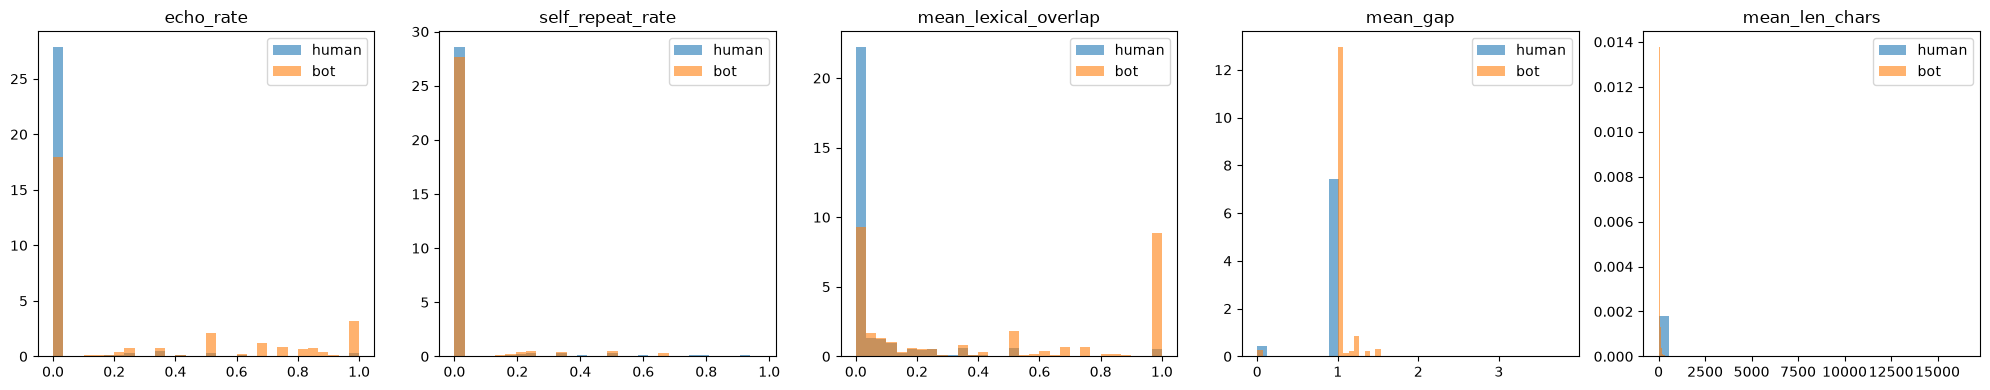

In [18]:
import matplotlib.pyplot as plt

key_feats = ["echo_rate", "self_repeat_rate", "mean_lexical_overlap", "mean_gap", "mean_len_chars"]
fig, axes = plt.subplots(1, len(key_feats), figsize=(20, 4))
for ax, col in zip(axes, key_feats):
    ax.hist(train_feats.loc[train_feats.is_bot == 0, col], bins=30, alpha=0.6, label="human", density=True)
    ax.hist(train_feats.loc[train_feats.is_bot == 1, col], bins=30, alpha=0.6, label="bot", density=True)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()